In [1]:
from pca_utils import *

# Import data

In [2]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS1/foci2/aggregated_data.csv"
path3 = "/mnt/c/users/helen/Desktop/190226/MGS2/foci2/aggregated_data.csv"
path4 = "/mnt/c/users/helen/Desktop/190226/MGS3/foci2/aggregated_data.csv"
path5 = "/mnt/c/users/helen/Desktop/190226/MGS4/foci2/aggregated_data.csv"
path6 = "/mnt/c/users/helen/Desktop/190226/MGS5/foci2/aggregated_data.csv"

df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)
df4 = pd.read_csv(path4)
df5 = pd.read_csv(path5)
df6 = pd.read_csv(path6)

df1["sample"] = "WT"
df2["sample"] = "MGS1"
df3["sample"] = "MGS2"
df4["sample"] = "MGS3"
df5["sample"] = "MGS4"
df6["sample"] = "MGS5"

combined_df = pd.concat(
    [df1, df2, df3, df4, df5, df6],
    ignore_index=True
)

### Clean data

In [3]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 204


# Correlation analysis

In [ ]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

In [ ]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

In [ ]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(2, 4, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [4]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

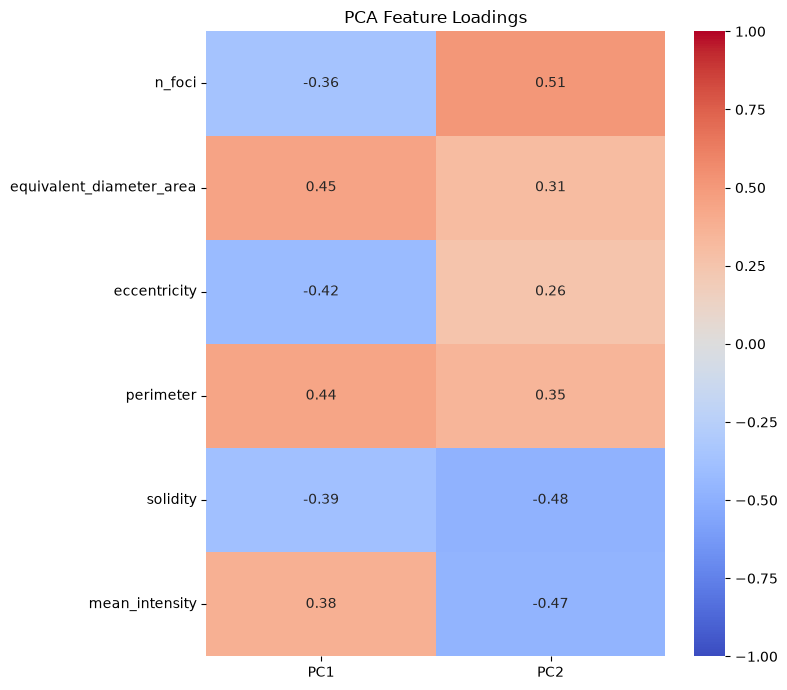

In [5]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [6]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS1   -0.007691  0.066479
MGS2   -0.209682  0.088539
MGS3    0.111234 -0.345828
MGS4    0.921361 -0.186651
MGS5   -0.222901  0.117413
WT     -0.630185  0.160216


In [ ]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

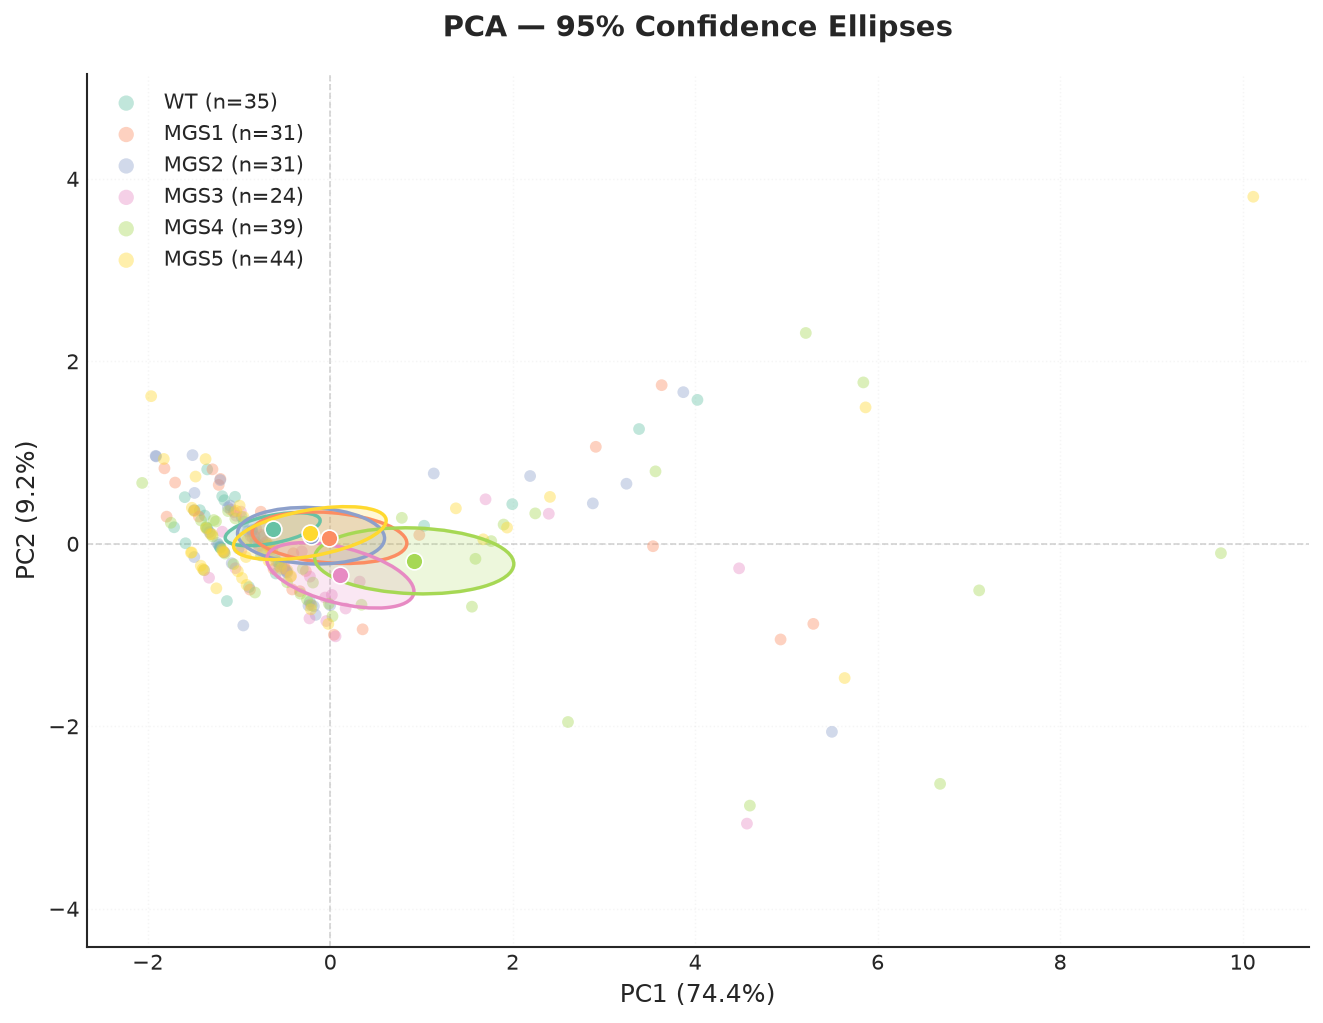

In [7]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    pca=pca,
    confidence=0.95,
    palette="Set2",
    centroid_size=65,
    show_bootstrap=False
)

In [ ]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS5")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats

### Centroids distances tree

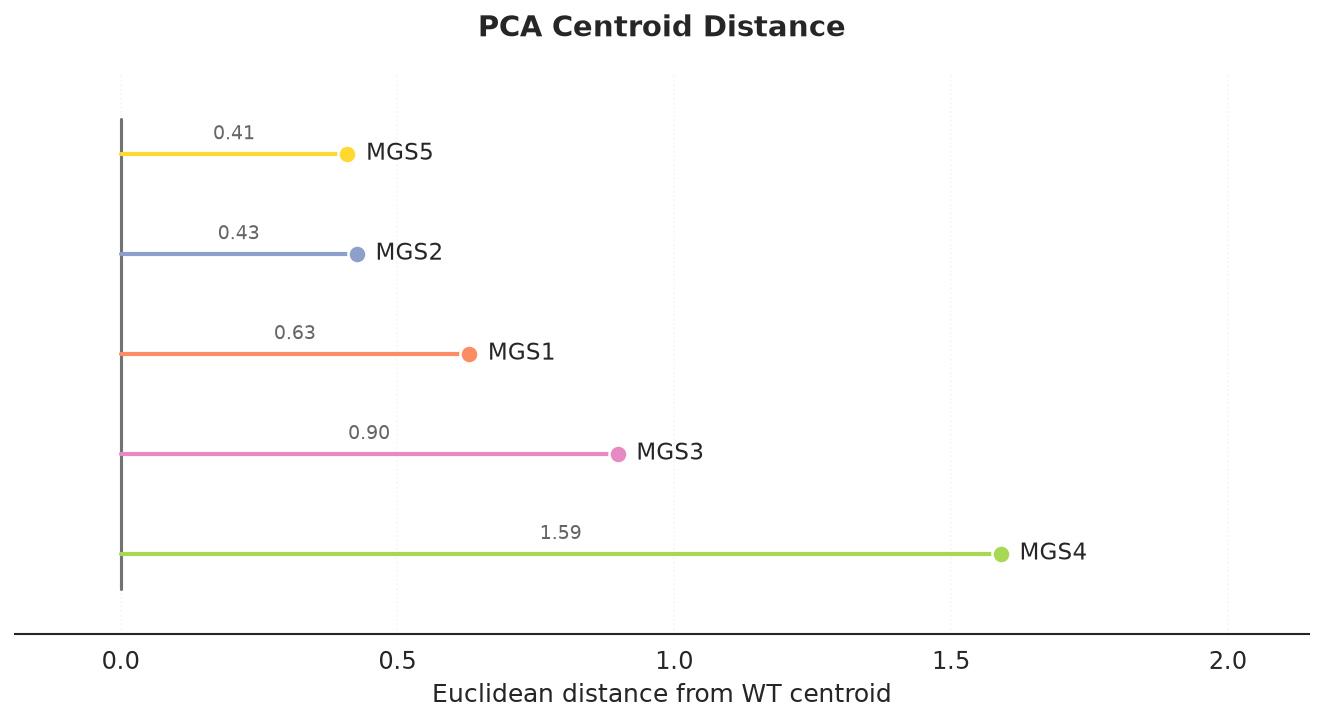

In [8]:
distances = plot_centroid_distance_tree(
    results,
    reference="WT",
    palette="Set2"
)

# Detect outliers

In [9]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,PC1,PC2,mahalanobis_distance,outlier
16,C2_MP_U2OS_fixed_WT_001.nd2_(series_25)_ROI_02...,83,13.0,4.068429,0.816497,0.835616,11.035534,71.000000,84.0,61.0,WT,3.385277,1.257921,3.228319,True
18,C2_MP_U2OS_fixed_WT_001.nd2_(series_27)_ROI_02...,84,16.0,4.513517,0.807260,0.820561,13.553301,86.973682,105.5,73.0,WT,4.025207,1.577487,3.863769,True
56,C2_MP_U2OS_fixed_MGS1_002.nd2_(series_07)_ROI_...,98,13.0,4.068429,0.816497,0.800000,11.639087,64.646294,80.5,55.0,MGS1,3.633012,1.738782,3.566813,True
83,C2_MP_U2OS_fixed_MGS2_002.nd2_(series_01)_ROI_...,7,18.0,4.787307,0.584013,0.952381,12.828427,318.500000,393.0,278.0,MGS2,5.499042,-2.060573,4.090696,True
87,C2_MP_U2OS_fixed_MGS2_002.nd2_(series_05)_ROI_...,74,15.5,4.441855,0.860487,0.801606,12.156854,98.803032,121.0,85.0,MGS2,3.870318,1.662015,3.293371,True
102,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_03)_ROI_...,8,13.5,4.139507,0.703547,0.867406,11.571068,173.663040,207.0,146.5,MGS3,4.481858,-0.268749,3.136311,True
104,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_05)_ROI_...,7,12.0,3.908820,0.638488,1.000000,10.485281,364.285706,411.0,319.0,MGS3,4.567722,-3.066766,3.956771,True
130,C2_MP_U2OS_fixed_MGS4_001.nd2_(series_11)_ROI_...,6,21.5,5.188373,0.514730,0.945165,14.242641,420.224686,491.0,367.5,MGS4,6.684701,-2.630921,3.193939,True
133,C2_MP_U2OS_fixed_MGS4_001.nd2_(series_14)_ROI_...,3,9.0,3.385138,0.617952,0.941176,7.621320,353.833344,374.0,324.0,MGS4,4.599913,-2.869417,3.081110,True
140,C2_MP_U2OS_fixed_MGS4_001.nd2_(series_21)_ROI_...,2,46.0,7.561732,0.779682,0.790244,27.106602,605.708344,765.5,518.0,MGS4,9.762768,-0.102929,3.174268,True


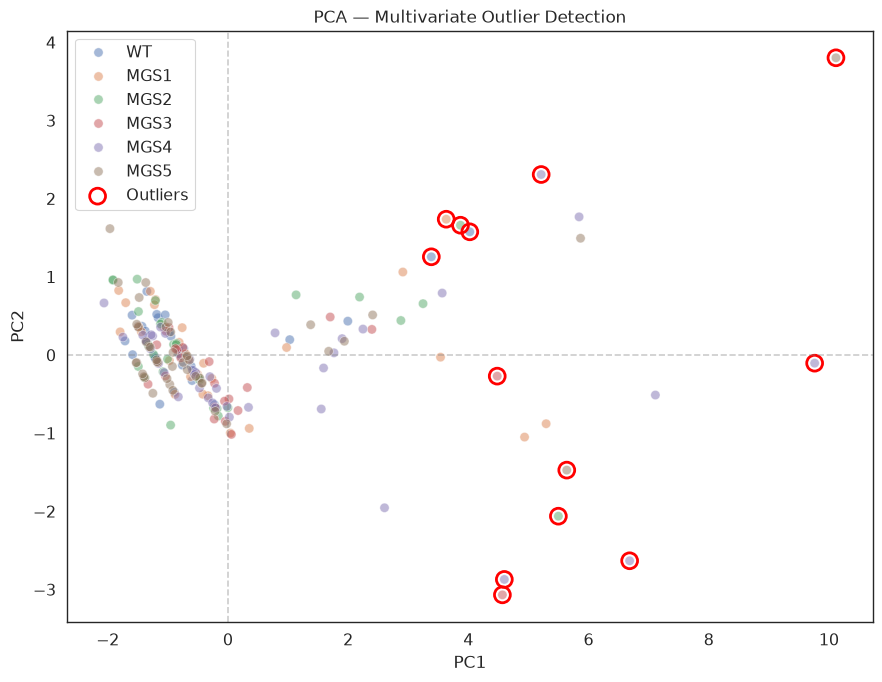

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

(191, 11)

In [12]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

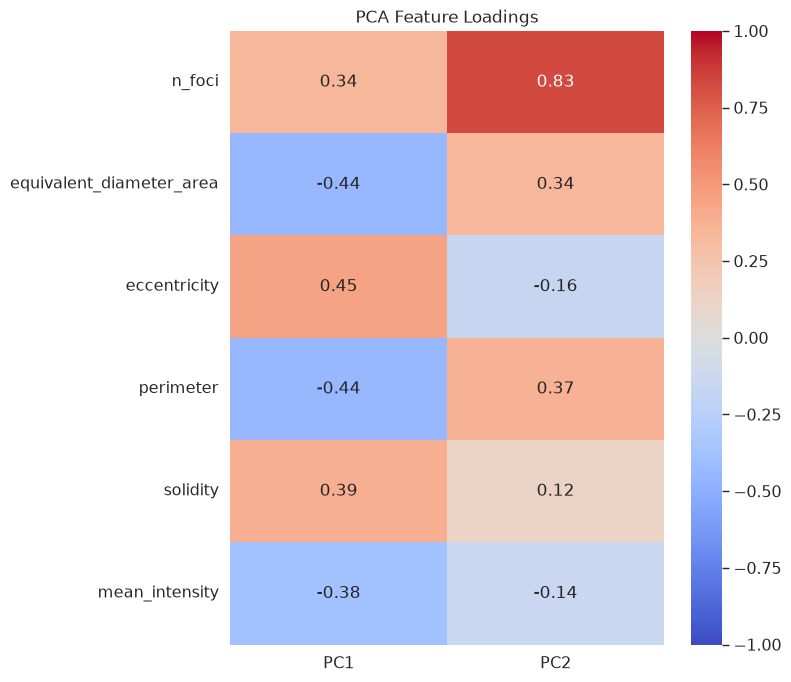

In [13]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

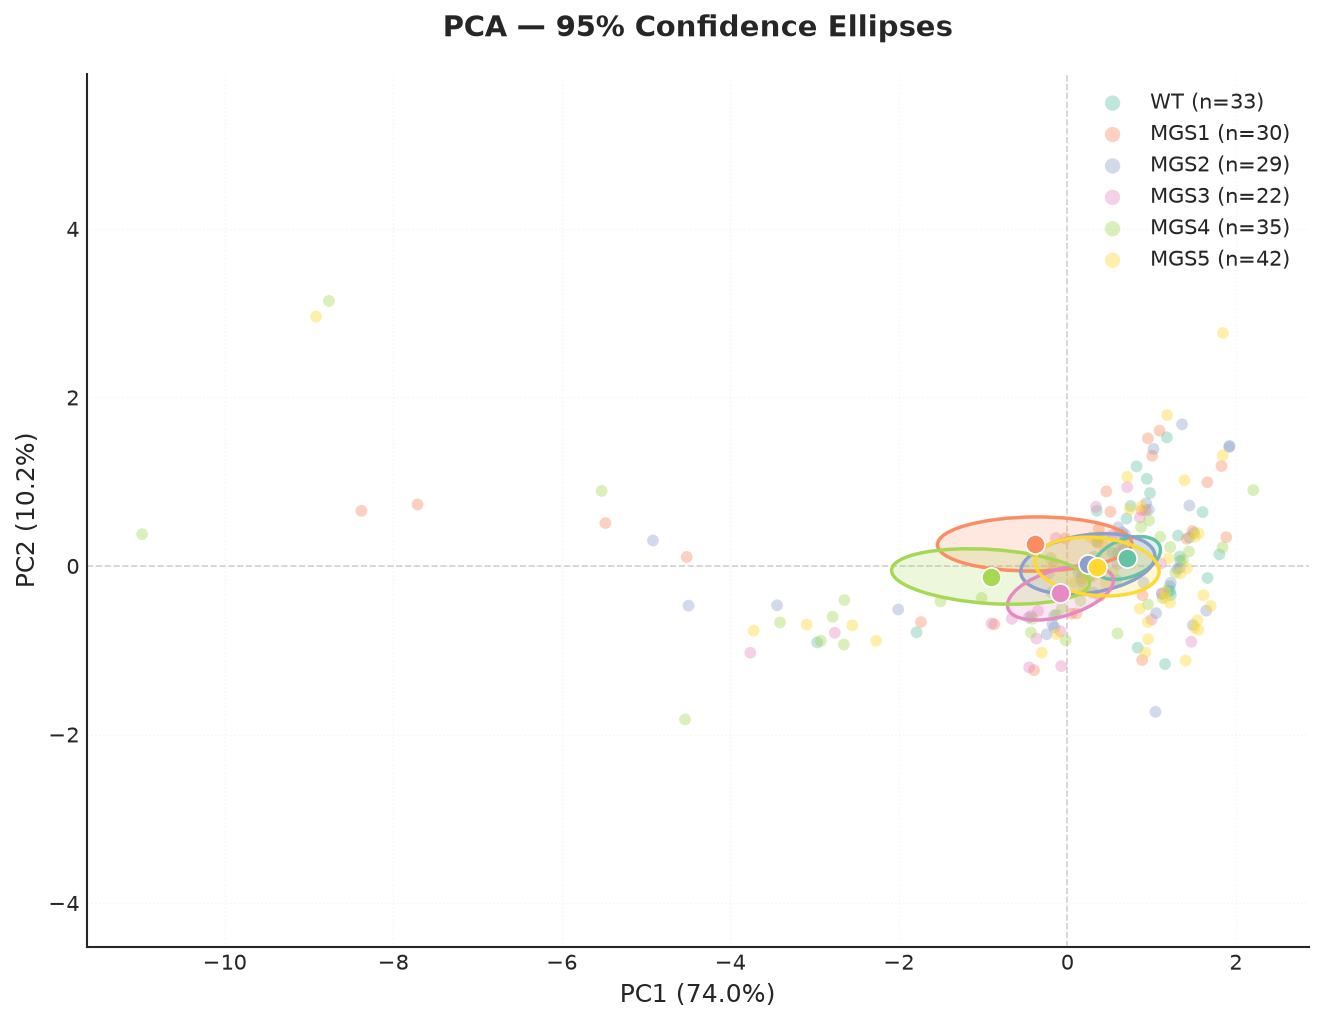

In [14]:
results = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

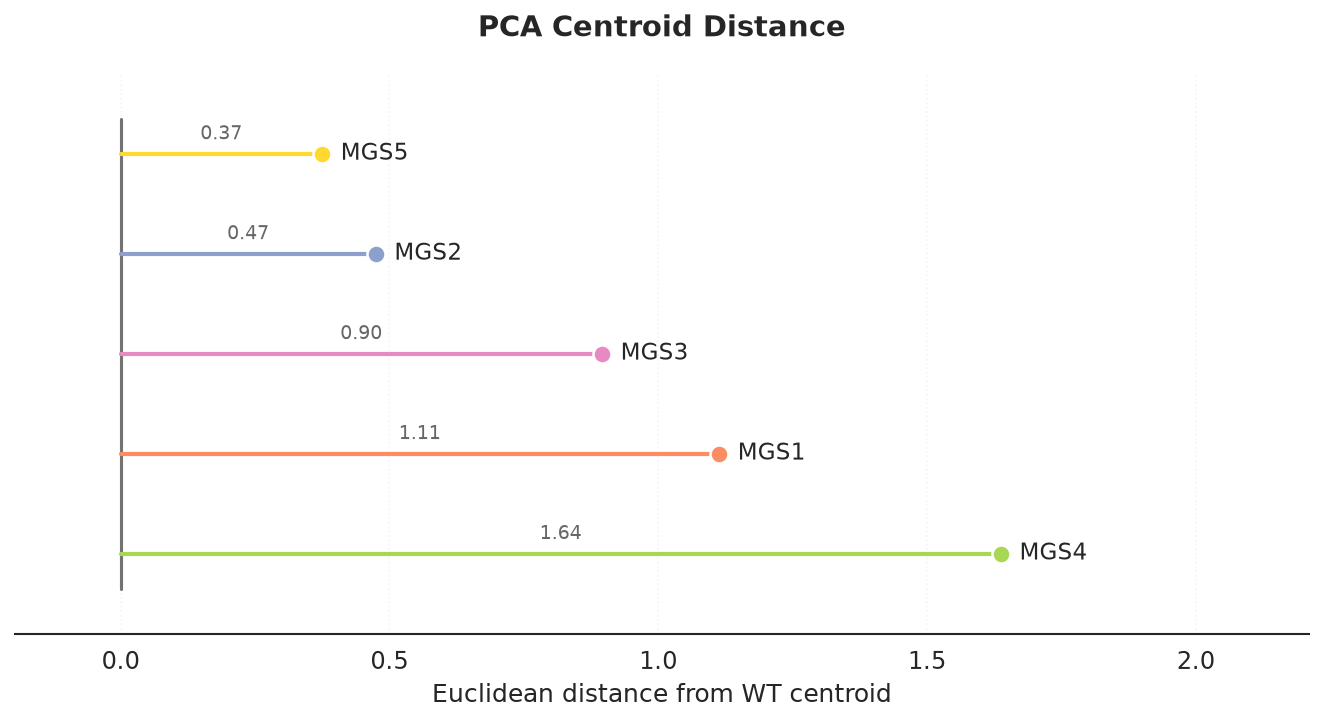

In [15]:
distances = plot_centroid_distance_tree(
    results,
    reference="WT",
    palette="Set2"
)

In [16]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS1   -0.388444  0.260751
MGS2    0.242993  0.024635
MGS3   -0.081722 -0.319017
MGS4   -0.910235 -0.125036
MGS5    0.351517 -0.006435
WT      0.712089  0.094788


In [ ]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

In [ ]:
subset = pca_df[(pca_df['sample'] == "WT") | (pca_df['sample'] == "MGS2")]

results_stats = pca_permanova(
    subset,
    group_col="sample"
)

results_stats